# 03 · What promotions and new competitors really do to sales

**Summary.**

**Promotions.** The report's +38.6% lift holds up. Promotions are network-wide and run in whole weeks, so the only valid
comparison is week against week. A fixed-effects model with store, year-month, weekday and day-of-month effects plus
holiday controls gives **+39.1% (95% CI +36.9% to +41.4%)**, with errors clustered by week, the unit of assignment.
Payday timing and holiday adjacency move the estimate by about two points each, in opposite directions.
* The lift splits into traffic +20.8% and ticket +15.2%.
* It fades from +62% on Monday to +25% on Friday.
* The following week shows no detectable dip (+1.5%, CI −2.9% to +6.0%).
* Format B stores gain only +18%.

Treating the 640K store-days as independent would understate the standard error twenty-fold. The loyalty promotion's
−1.9% is a seasonality artefact: compared with other stores on the same dates it is −0.3% (CI −0.5% to 0.0%).

**Competitors.** The published −6.8% median impact reproduces exactly (131 events, 34% losing 10%+). An event study
against same-state comparison stores gives a **mean of −7.9% (95% CI −9.8% to −6.0%)** and a median of −6.2%. Every
check supports a causal reading:
* Pre-trends are flat (no lead beyond 0.8%).
* Random placebo openings centre on zero (95% range −0.7% to +0.7%, p = 0.003).
* The same stores a year earlier show nothing.
* The loss falls with distance, from −16% under 500 m to under 2% beyond 5 km.

**Actions.** Keep the promotion calendar and test its shape (length, format B), not its existence. Test the loyalty
promotion before renewing it. Treat a competitor opening within 2 km as a −8% to −16% step change in the forecast and
the staffing plan.

In [1]:
import os, sys, warnings
from pathlib import Path
os.environ.setdefault("OMP_NUM_THREADS", "4")   # share the laptop: other projects run at the same time
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ds" / "dskit").exists())
sys.path.insert(0, str(ROOT / "ds"))
warnings.simplefilter("ignore")              # library warnings print local paths into the outputs
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dskit import set_style, PALETTE, headline, savefig, audit, eda, evaluate, explain, select, report
import features as F
from IPython.display import display
set_style(); pd.set_option("display.float_format", lambda v: f"{v:,.4f}"); pd.set_option("display.width", 160)
FIG, METRICS, SEED = ROOT / "ds" / "figures", ROOT / "ds" / "reports" / "metrics.json", 42
import time
T_START = time.perf_counter()


def fig_title(fig, title, subtitle=None):
    """Insight title and method subtitle for a multi-panel figure."""
    h = fig.get_figheight()
    fig.suptitle(title, x=0.01, y=1 - 0.04 / h, ha="left", va="top", fontsize=14, fontweight="bold", color=PALETTE["ink"])
    if subtitle:
        fig.text(0.01, 1 - 0.36 / h, subtitle, ha="left", va="top", fontsize=10, color="#5A6478")
    fig.tight_layout(rect=(0, 0, 1, 1 - (0.50 if subtitle else 0.30) / h), pad=0.6)


PUBLISHED = {"promo_sales": 0.386, "promo_traffic": 0.196, "promo_ticket": 0.157, "loyalty_month": -0.019,
             "competition_events": 131, "competition_median_impact": -0.068, "share_losing_10pct": 0.34}
pct = lambda b: np.expm1(b)                    # log-point coefficient -> % change

In [2]:
tr, stores, fact, X0 = F.build_frame(ROOT)
del tr
print(f"{len(fact):,} open store-days, {fact['StoreKey'].nunique():,} stores")

844,338 open store-days, 1,115 stores


## Part A · Promotions

### A1. The published numbers

The report's uplift compares promotion and regular days on the same weekday (Monday-Friday) and averages the five ratios.

In [3]:
mf = X0[X0["dow"] < 5].copy()
g = mf.groupby(["dow", "Promo"]).agg(sales=("Sales", "sum"), customers=("Customers", "sum"), n=("Sales", "size"))
naive = pd.Series({
    "sales": ((g["sales"] / g["n"]).unstack().pipe(lambda t: t[1] / t[0] - 1)).mean(),
    "traffic": ((g["customers"] / g["n"]).unstack().pipe(lambda t: t[1] / t[0] - 1)).mean(),
    "ticket": ((g["sales"] / g["customers"]).unstack().pipe(lambda t: t[1] / t[0] - 1)).mean()})
print(f"Weekday-matched uplift: sales {naive['sales']:+.1%}, traffic {naive['traffic']:+.1%}, ticket {naive['ticket']:+.1%}")
assert abs(naive["sales"] - PUBLISHED["promo_sales"]) < 0.001 and abs(naive["traffic"] - PUBLISHED["promo_traffic"]) < 0.001
assert abs(naive["ticket"] - PUBLISHED["promo_ticket"]) < 0.001

Weekday-matched uplift: sales +38.6%, traffic +19.6%, ticket +15.7%


### A2. What can and cannot identify the effect

Notebook 01 found that promotions are switched on for the **whole network for whole Monday-Friday weeks**, roughly
every other week, and more often in the first and third weeks of the month. Three consequences:

* There is no untreated store on a promotion day, so no cross-sectional control exists. The effect is identified only
  by comparing promotion weeks with non-promotion weeks.
* Anything that differs between those weeks confounds the raw comparison: payday (day of month), season, holidays,
  the growth trend. These can be absorbed with fixed effects, as long as the fixed effects are coarser than the week.
  **Week fixed effects would absorb the promotion entirely**, so the time controls are year-month, weekday and
  day-of-month.
* The unit of assignment is the week. Store-days within a week share the same treatment and the same shocks, so
  standard errors must be clustered by week. The effective sample is about 135 weeks, not 640K store-days.

The model, on Monday-Friday open store-days:

$$\log(\text{sales}_{it}) = \alpha_i + \gamma_{\text{year-month}(t)} + \delta_{\text{weekday}(t)} + \theta_{\text{day of month}(t)} + \beta\,\text{Promo}_t + \lambda' \text{holidays}_{it} + \varepsilon_{it}$$

Store, year-month, weekday and day-of-month fixed effects are absorbed by alternating projections (`features.fe_ols`,
unit-tested on synthetic data); $100(e^{\beta}-1)$ is the promotion lift in %.

In [4]:
mf["ls"] = np.log(mf["Sales"])
mf["lc"] = np.log(mf["Customers"].clip(lower=1))
mf["lt"] = mf["ls"] - mf["lc"]
mf["ym"] = mf["Date"].dt.year * 100 + mf["Date"].dt.month
iso = mf["Date"].dt.isocalendar()
mf["week"] = iso["year"].astype(int) * 100 + iso["week"].astype(int)
mf["pre_hol"] = (mf["days_to_hol"] <= 2).astype(int)          # the stock-up days before a closure (notebook 01)
mf["post_hol"] = (mf["days_since_hol"] <= 2).astype(int)
CTRL = ["state_hol", "SchoolHoliday", "pre_hol", "post_hol"]
specs = {
    "1. Store FE only": (["Promo"], ["StoreKey"]),
    "2. + weekday": (["Promo"], ["StoreKey", "dow"]),
    "3. + year-month": (["Promo"], ["StoreKey", "dow", "ym"]),
    "4. + day of month": (["Promo"], ["StoreKey", "dow", "ym", "dom"]),
    "5. + holiday controls": (["Promo", *CTRL], ["StoreKey", "dow", "ym", "dom"]),
}
rows = []
for name, (x, fe) in specs.items():
    r = F.fe_ols(mf, "ls", x, fe, cluster="week").loc["Promo"]
    rows.append({"specification": name, "lift": pct(r["coef"]), "CI low": pct(r["ci_low"]), "CI high": pct(r["ci_high"]), "clusters (weeks)": int(r["clusters"])})
spec_tab = pd.DataFrame(rows).set_index("specification")
display(spec_tab.style.format({"lift": "{:+.1%}", "CI low": "{:+.1%}", "CI high": "{:+.1%}"}))
final = F.fe_ols(mf, "ls", ["Promo", *CTRL], ["StoreKey", "dow", "ym", "dom"], cluster="week")
display(final.assign(effect=lambda t: pct(t["coef"])).style.format(precision=4))

,lift,CI low,CI high,clusters (weeks)
specification,,,,
1. Store FE only,+39.3%,+35.3%,+43.4%,135
2. + weekday,+39.1%,+35.1%,+43.2%,135
3. + year-month,+39.1%,+36.4%,+41.8%,135
4. + day of month,+37.3%,+34.9%,+39.8%,135
5. + holiday controls,+39.1%,+36.9%,+41.4%,135


,coef,se,t,ci_low,ci_high,clusters,effect
Promo,0.3300,0.0082,40.1853,0.3138,0.3463,135,0.3910
state_hol,-0.2048,0.0345,-5.9429,-0.2729,-0.1366,135,-0.1852
SchoolHoliday,-0.0099,0.0098,-1.0060,-0.0294,0.0096,135,-0.0099
pre_hol,0.0856,0.0238,3.6012,0.0386,0.1327,135,0.0894
post_hol,0.1507,0.0166,9.0886,0.1179,0.1835,135,0.1627


### A3. How wrong would the standard errors be?

In [5]:
se = pd.Series({
    "naive (independent store-days)": F.fe_ols(mf, "ls", ["Promo", *CTRL], ["StoreKey", "dow", "ym", "dom"]).loc["Promo", "se"],
    "clustered by store": F.fe_ols(mf, "ls", ["Promo", *CTRL], ["StoreKey", "dow", "ym", "dom"], cluster="StoreKey").loc["Promo", "se"],
    "clustered by week (assignment unit)": final.loc["Promo", "se"]}, name="standard error of beta")
display(se.to_frame().assign(**{"relative to week-clustered": lambda t: t.iloc[:, 0] / se.iloc[-1]}).style.format("{:.4f}"))

,standard error of beta,relative to week-clustered
naive (independent store-days),0.0004,0.0494
clustered by store,0.0027,0.3265
clustered by week (assignment unit),0.0082,1.0000


Treating the 640K store-days as independent understates the uncertainty twenty-fold. Clustering by store, the instinctive
choice for panel data, still understates it three-fold, because every store shares the same promotion weeks. With week
clustering the 95% interval is about ±2.3 points. That is still precise, because 135 weeks of alternating promotions make
a strong natural experiment. But any test of promotion variants has to be powered on weeks, not on store-days.

### A4. Cross-check against statsmodels

On a random 60-store subsample, the same specification fitted with explicit dummies in statsmodels (cluster-robust by
week) must give the same coefficient as the alternating-projections estimator.

In [6]:
import statsmodels.formula.api as smf

rng = np.random.default_rng(SEED)
sub = mf[mf["StoreKey"].isin(rng.choice(mf["StoreKey"].unique(), 60, replace=False))]
sm_fit = smf.ols("ls ~ Promo + state_hol + SchoolHoliday + pre_hol + post_hol + C(StoreKey) + C(ym) + C(dow) + C(dom)", data=sub).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(sub["week"])[0]})
mine = F.fe_ols(sub, "ls", ["Promo", *CTRL], ["StoreKey", "dow", "ym", "dom"], cluster="week").loc["Promo"]
xcheck = pd.DataFrame({"statsmodels (dummies)": [sm_fit.params["Promo"], sm_fit.bse["Promo"]], "features.fe_ols": [mine["coef"], mine["se"]]},
                      index=["coefficient", "standard error"])
display(xcheck)
assert abs(xcheck.iloc[0, 0] - xcheck.iloc[0, 1]) < 1e-6 and abs(xcheck.iloc[1, 0] / xcheck.iloc[1, 1] - 1) < 0.05

,statsmodels (dummies),features.fe_ols
coefficient,0.3379,0.3379
standard error,0.0088,0.0088


### A5. Traffic or basket? And does the promotion just pull sales forward?

In [7]:
dec = {}
for lab, y in [("sales", "ls"), ("traffic (customers)", "lc"), ("ticket (sales per customer)", "lt")]:
    r = F.fe_ols(mf, y, ["Promo", *CTRL], ["StoreKey", "dow", "ym", "dom"], cluster="week").loc["Promo"]
    dec[lab] = {"naive": naive[{"sales": "sales", "traffic (customers)": "traffic", "ticket (sales per customer)": "ticket"}[lab]],
                "fixed effects": pct(r["coef"]), "CI low": pct(r["ci_low"]), "CI high": pct(r["ci_high"])}
dec = pd.DataFrame(dec).T
display(dec.style.format("{:+.1%}"))
wk = mf.groupby("week")["Promo"].max()
mf["promo_last_week"] = mf["week"].map(wk.shift(1)).fillna(0)
pf = F.fe_ols(mf, "ls", ["Promo", "promo_last_week", *CTRL], ["StoreKey", "dow", "ym", "dom"], cluster="week")
print(f"Week after a promotion vs a week after a regular week: {pct(pf.loc['promo_last_week', 'coef']):+.1%} "
      f"(95% CI {pct(pf.loc['promo_last_week', 'ci_low']):+.1%} to {pct(pf.loc['promo_last_week', 'ci_high']):+.1%})")
by_dow = {}
for dw, gg in mf.groupby("dow"):
    r = F.fe_ols(gg, "ls", ["Promo", *CTRL], ["StoreKey", "ym", "dom"], cluster="week").loc["Promo"]
    by_dow[["Mon", "Tue", "Wed", "Thu", "Fri"][dw]] = {"lift": pct(r["coef"]), "CI low": pct(r["ci_low"]), "CI high": pct(r["ci_high"])}
by_dow = pd.DataFrame(by_dow).T
display(by_dow.style.format("{:+.1%}"))

,naive,fixed effects,CI low,CI high
sales,+38.6%,+39.1%,+36.9%,+41.4%
traffic (customers),+19.6%,+20.8%,+19.3%,+22.2%
ticket (sales per customer),+15.7%,+15.2%,+14.5%,+15.8%


Week after a promotion vs a week after a regular week: +1.5% (95% CI -2.9% to +6.0%)


,lift,CI low,CI high
Mon,+62.2%,+58.6%,+65.9%
Tue,+48.6%,+45.1%,+52.1%
Wed,+37.2%,+33.9%,+40.5%
Thu,+30.2%,+28.5%,+31.9%
Fri,+25.4%,+23.7%,+27.1%


* **Traffic and basket.** After controls, traffic is +20.8% and ticket +15.2%. The published "about half more
  shoppers, half bigger baskets" holds.
* **No pull-forward across weeks.** The week after a promotion sells +1.5% (CI −2.9% to +6.0%) relative to a week after
  a regular week: no detectable hangover.
* **Front-loaded within the week.** The lift fades from +62% on Monday to +25% on Friday. That is either a launch effect
  or pull-forward inside the week; either way the week as a whole gains about 39%, and Mondays need the most staff.

### A6. Does the lift differ by store format?

In [8]:
fmt = stores.set_index("Store")["StoreType"].str.upper()
het = {}
for f_, gg in mf.assign(fmt=mf["StoreKey"].map(fmt)).groupby("fmt"):
    r = F.fe_ols(gg, "ls", ["Promo", *CTRL], ["StoreKey", "dow", "ym", "dom"], cluster="week").loc["Promo"]
    het[f"Format {f_} ({gg['StoreKey'].nunique()} stores)"] = {"lift": pct(r["coef"]), "CI low": pct(r["ci_low"]), "CI high": pct(r["ci_high"])}
het = pd.DataFrame(het).T
display(het.style.format("{:+.1%}"))

,lift,CI low,CI high
Format A (602 stores),+37.3%,+35.2%,+39.5%
Format B (17 stores),+18.1%,+16.2%,+19.9%
Format C (148 stores),+40.7%,+38.2%,+43.3%
Format D (348 stores),+42.7%,+40.3%,+45.2%


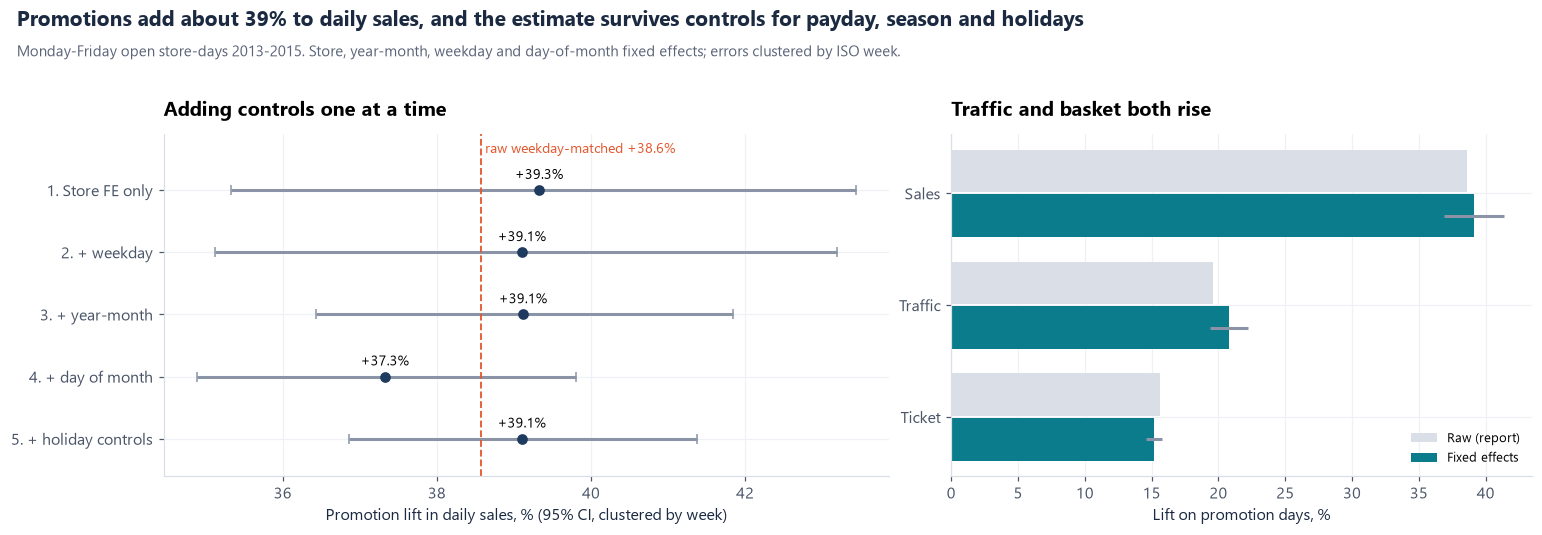

In [9]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.25, 1]})
yy = np.arange(len(spec_tab))[::-1]
a1.errorbar(spec_tab["lift"] * 100, yy, xerr=[(spec_tab["lift"] - spec_tab["CI low"]) * 100, (spec_tab["CI high"] - spec_tab["lift"]) * 100],
            fmt="o", color=PALETTE["navy"], ecolor=PALETTE["grey"], capsize=3)
a1.axvline(naive["sales"] * 100, color=PALETTE["coral"], ls="--", lw=1.2)
a1.text(naive["sales"] * 100, len(spec_tab) - 0.45, f" raw weekday-matched {naive['sales']:+.1%}", color=PALETTE["coral"], fontsize=9, va="bottom")
for v, y_ in zip(spec_tab["lift"], yy):
    a1.text(v * 100, y_ + 0.18, f"{v:+.1%}", ha="center", fontsize=9)
a1.set_yticks(yy, spec_tab.index)
a1.set(xlabel="Promotion lift in daily sales, % (95% CI, clustered by week)", title="Adding controls one at a time")
a1.set_ylim(-0.6, len(spec_tab) - 0.1)
yy2 = np.arange(len(dec))[::-1]
a2.barh(yy2 + 0.2, dec["naive"] * 100, height=0.38, color=PALETTE["light"], label="Raw (report)")
a2.barh(yy2 - 0.2, dec["fixed effects"] * 100, height=0.38, color=PALETTE["teal"], label="Fixed effects",
        xerr=[(dec["fixed effects"] - dec["CI low"]) * 100, (dec["CI high"] - dec["fixed effects"]) * 100], ecolor=PALETTE["grey"])
a2.set_yticks(yy2, [i.split(" (")[0].title() for i in dec.index])
a2.set(xlabel="Lift on promotion days, %", title="Traffic and basket both rise")
a2.legend(fontsize=8.5, loc="lower right")
fig_title(fig, f"Promotions add about {dec.loc['sales', 'fixed effects']:.0%} to daily sales, and the estimate survives controls for payday, season and holidays",
          "Monday-Friday open store-days 2013-2015. Store, year-month, weekday and day-of-month fixed effects; errors clustered by ISO week.")
savefig(fig, "03-promo-effect", FIG); plt.show()

### A7. The loyalty promotion (Promo2)

The report shows loyalty-promotion stores selling 1.9% **less** in their promotion months than in other months. Those
months are fixed calendars (Jan/Apr/Jul/Oct and so on), so the raw comparison mixes the promotion with the season.
Unlike the weekly promotion, the loyalty months differ **between stores on the same day**, so date fixed effects can be
used: each store is compared with stores outside their promotion month on the very same date.

In [10]:
lp = X0[X0["Promo2"] == 1]
raw_loyal = lp.groupby("LoyaltyPromoMonth")["Sales"].mean()
raw_loyal = raw_loyal[1] / raw_loyal[0] - 1
print(f"Raw (report definition): {raw_loyal:+.1%} (published {PUBLISHED['loyalty_month']:+.1%})")
assert abs(raw_loyal - PUBLISHED["loyalty_month"]) < 0.001
al = X0.assign(ls=np.log(X0["Sales"]))
loy = F.fe_ols(al, "ls", ["LoyaltyPromoMonth"], ["StoreKey", "Date"], cluster="StoreKey").loc["LoyaltyPromoMonth"]
loy_in = F.fe_ols(al[al["Promo2"] == 1], "ls", ["LoyaltyPromoMonth"], ["StoreKey", "Date"], cluster="StoreKey").loc["LoyaltyPromoMonth"]
loyal_tab = pd.DataFrame({"estimate": [raw_loyal, pct(loy_in["coef"]), pct(loy["coef"])],
                          "CI low": [np.nan, pct(loy_in["ci_low"]), pct(loy["ci_low"])], "CI high": [np.nan, pct(loy_in["ci_high"]), pct(loy["ci_high"])]},
                         index=["raw: promotion months vs other months", "store + date FE, loyalty stores only", "store + date FE, all stores"])
display(loyal_tab.style.format("{:+.2%}", na_rep="-"))

Raw (report definition): -1.9% (published -1.9%)


,estimate,CI low,CI high
raw: promotion months vs other months,-1.91%,-,-
"store + date FE, loyalty stores only",-0.33%,-0.57%,-0.08%
"store + date FE, all stores",-0.26%,-0.51%,-0.01%


The raw −1.9% compares loyalty months (Jan/Apr/Jul/Oct for most stores) with other months, so it mixes the promotion with
the season. Compared with other stores on the same date, the effect is −0.3% (CI −0.5% to 0.0%). The loyalty promotion
neither lifts nor meaningfully hurts sales in its months. Either it works through something not measured here (retention,
visit frequency across months) or it does not work. A store-holdout test before the next renewal would settle it.

## Part B · Competitor openings

### B1. The published estimate

The ETL compares each store's mean daily sales in the 90 days before a competitor opened with days 30-150 after,
net of the network's change over the same days. Reproduce it exactly:

In [11]:
etl_ev = F.etl_competition_events(fact, stores)
etl_summary = pd.Series({"events": len(etl_ev), "median impact": etl_ev["ImpactPct"].median(), "mean impact": etl_ev["ImpactPct"].mean(),
                         "share losing 10%+": (etl_ev["ImpactPct"] <= -0.10).mean()})
print(etl_summary.to_string(float_format=lambda v: f"{v:+.3f}"))
assert len(etl_ev) == PUBLISHED["competition_events"] and round(etl_ev["ImpactPct"].median(), 3) == PUBLISHED["competition_median_impact"]
assert abs((etl_ev["ImpactPct"] <= -0.10).mean() - PUBLISHED["share_losing_10pct"]) < 0.005

events              +131.000
median impact         -0.068
mean impact           -0.078
share losing 10%+     +0.344


Two weaknesses: the comparison group is the whole network (including other stores that gained a competitor and stores
in other states with different school holidays), and there is no check that treated stores were on the same path as
the others **before** the opening. An event study fixes both.

### B2. Event study with a clean, same-state comparison group

* **Treated**: the stores whose (nearest) competitor opened between April 2013 and January 2015 (the ETL's window).
* **Comparison**: stores whose competitor was already open before July 2012, i.e. with no recorded opening in the sample
  period. Each treated store is compared with the comparison stores **in the same state, in the same week**, which
  removes state-specific holidays and regional shocks.
* **Outcome**: weekly mean log daily sales (Monday-Saturday, weeks with 4+ trading days), relative to the same-state
  comparison mean, re-based to the store's own 13 pre-opening weeks.
* **Timing**: the source records only the opening **month**, so week 0 is the week containing the 1st of that month and
  the effect can ramp in over weeks 0-4. The effect window is weeks 5-21 (about days 30-150, as in the ETL).

In [12]:
state_of = stores.set_index("Store")["State"]
controls = stores.loc[stores["CompOpen"] < "2012-07-01", "Store"]
treated = stores[stores["CompOpen"].between("2013-04-01", "2015-01-01")]
P = F.relative_weekly_sales(fact, state_of, controls)
E = F.event_profile(P, treated["Store"], treated["CompOpen"])
eff = F.event_effects(E)
print(f"{len(controls)} comparison stores; {len(treated)} openings in the window, {len(E)} with enough pre and post weeks")
rng = np.random.default_rng(SEED)
B = np.array([E.iloc[rng.integers(0, len(E), len(E))].mean().to_numpy() for _ in range(1000)])
prof = pd.DataFrame({"effect": E.mean(), "lo": np.nanpercentile(B, 2.5, axis=0), "hi": np.nanpercentile(B, 97.5, axis=0)})
leads = prof.loc[-13:-1]
slope = np.polyfit(leads.index, leads["effect"], 1)[0]
slope_boot = np.array([np.polyfit(np.arange(-13, 0), b[:13], 1)[0] for b in B])
avg_eff = np.expm1(E.loc[:, 5:21].mean(axis=1).mean())
avg_boot = np.expm1(B[:, 18:35].mean(axis=1))
pre_tab = pd.Series({"largest |lead| (weeks -13..-1)": leads["effect"].abs().max(), "lead CIs that exclude 0": int(((leads["lo"] > 0) | (leads["hi"] < 0)).sum()),
                     "pre-trend slope per week": slope, "slope 95% CI low": np.percentile(slope_boot, 2.5), "slope 95% CI high": np.percentile(slope_boot, 97.5)})
display(pre_tab.to_frame("pre-trend check").style.format("{:.4f}"))
res_tab = pd.DataFrame({
    "ETL (published)": [len(etl_ev), etl_ev["ImpactPct"].median(), etl_ev["ImpactPct"].mean(), (etl_ev["ImpactPct"] <= -0.10).mean(), np.nan, np.nan],
    "Event study": [len(E), eff.median(), avg_eff, (eff <= -0.10).mean(), np.percentile(avg_boot, 2.5), np.percentile(avg_boot, 97.5)]},
    index=["events", "median store impact", "mean impact", "share losing 10%+", "mean impact 95% CI low", "mean impact 95% CI high"])
display(res_tab.style.format("{:+.3f}"))

508 comparison stores; 141 openings in the window, 131 with enough pre and post weeks


,pre-trend check
largest |lead| (weeks -13..-1),0.0080
lead CIs that exclude 0,0.0000
pre-trend slope per week,0.0003
slope 95% CI low,-0.0007
slope 95% CI high,0.0013


,ETL (published),Event study
events,+131.000,+131.000
median store impact,-0.068,-0.062
mean impact,-0.078,-0.079
share losing 10%+,+0.344,+0.313
mean impact 95% CI low,+nan,-0.098
mean impact 95% CI high,+nan,-0.060


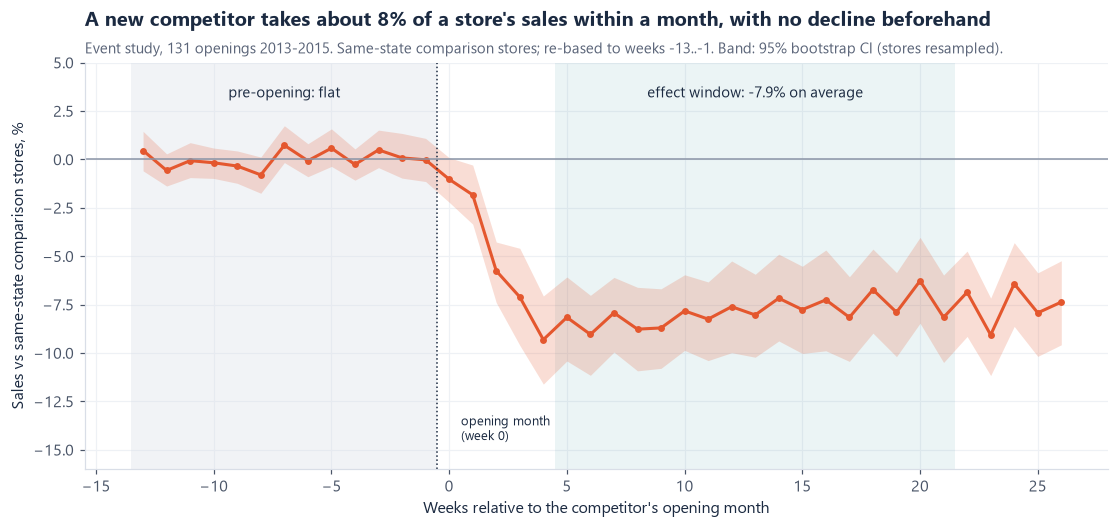

In [13]:
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.axvspan(-13.5, -0.5, color=PALETTE["light"], alpha=0.35, lw=0)
ax.axvspan(4.5, 21.5, color=PALETTE["teal"], alpha=0.08, lw=0)
ax.fill_between(prof.index, np.expm1(prof["lo"]) * 100, np.expm1(prof["hi"]) * 100, color=PALETTE["coral"], alpha=0.2, lw=0)
ax.plot(prof.index, np.expm1(prof["effect"]) * 100, color=PALETTE["coral"], marker="o", ms=3.5)
ax.axhline(0, color=PALETTE["grey"], lw=1)
ax.axvline(-0.5, color=PALETTE["ink"], lw=1, ls=":")
ax.text(-7, 3.2, "pre-opening: flat", ha="center", fontsize=9.5, color=PALETTE["ink"])
ax.text(13, 3.2, f"effect window: {avg_eff:+.1%} on average", ha="center", fontsize=9.5, color=PALETTE["ink"])
ax.text(0.5, -14.5, "opening month\n(week 0)", fontsize=8.5, color=PALETTE["ink"])
ax.set(xlabel="Weeks relative to the competitor's opening month", ylabel="Sales vs same-state comparison stores, %", ylim=(-16, 5))
headline(ax, f"A new competitor takes about {abs(avg_eff):.0%} of a store's sales within a month, with no decline beforehand",
         f"Event study, {len(E)} openings 2013-2015. Same-state comparison stores; re-based to weeks -13..-1. Band: 95% bootstrap CI (stores resampled).")
savefig(fig, "03-competitor-event-study", FIG); plt.show()

* **Pre-trends are flat.** No lead exceeds 0.8%, every lead's CI includes zero, and the pre-period slope is 0.03% per
  week (CI −0.07% to +0.13%). Treated stores were not declining before their competitor arrived, which is what the
  design needs.
* **Shape.** Sales fall across the opening month (weeks 0-4, as expected when only the month is known), then settle at
  about −8%, with no recovery by week 26.
* **Agreement with the ETL.** Median −6.2% vs −6.8%, mean −7.9% (95% CI −9.8% to −6.0%) vs −7.8%, share losing 10%+
  31% vs 34%. The published number is confirmed, now with an interval and a pre-trend check.

### B3. Placebo tests

1. **Fake openings in untreated stores.** Give 131 randomly chosen comparison stores the opening dates of the real events
   and run the same estimator; repeat 300 times. If the method manufactures effects (seasonality, mean reversion), the
   placebo distribution will not centre on zero.
2. **The same stores, one year earlier.** Shift each real opening back 52 weeks (where the data allow). A store that
   was already declining before its competitor arrived would show an "effect" here.

In [14]:
pool = controls[controls.isin(P.index)].to_numpy()
placebo = []
for b in range(300):
    ids = rng.choice(pool, len(treated), replace=False)
    dates = treated["CompOpen"].sample(len(treated), replace=True, random_state=b).to_numpy()
    placebo.append(F.event_effects(F.event_profile(P, ids, dates)).median())
placebo = np.array(placebo)
p_perm = (np.sum(placebo <= eff.median()) + 1) / (len(placebo) + 1)
E_shift = F.event_profile(P, treated["Store"], treated["CompOpen"] - pd.Timedelta(weeks=52))
eff_shift = F.event_effects(E_shift)
plac_tab = pd.Series({"real openings: median impact": eff.median(), "placebo (random stores): median of 300 medians": np.median(placebo),
                      "placebo 95% range low": np.percentile(placebo, 2.5), "placebo 95% range high": np.percentile(placebo, 97.5),
                      "permutation p-value (one-sided)": p_perm, f"same stores 52 weeks earlier ({len(E_shift)} events): median": eff_shift.median()})
display(plac_tab.to_frame("value").style.format("{:+.4f}"))

,value
real openings: median impact,-0.0621
placebo (random stores): median of 300 medians,+0.0007
placebo 95% range low,-0.0069
placebo 95% range high,+0.0065
permutation p-value (one-sided),+0.0033
same stores 52 weeks earlier (67 events): median,+0.0036


Fake openings in untreated stores give a median impact of +0.07%, with 95% of the 300 draws between −0.7% and +0.7%. None
comes close to the real −6.2% (permutation p = 0.003, the smallest possible with 300 draws). The same treated stores one
year before their opening (67 events with enough data) show +0.4%. The estimator does not manufacture effects, and the
treated stores were not already on a different path.

### B4. Distance matters: a dose-response check

If the effect is real, a competitor next door should hurt more than one 10 km away. Impact by the distance of the new
(now nearest) competitor, with bootstrap intervals for the median:

In [15]:
band = F.competition_band(treated.set_index("Store").loc[E.index, "CompetitionDistance"])
order = ["Under 0.5 km", "0.5-2 km", "2-5 km", "5-15 km", "15 km+"]
dist_rows = []
for bnd in order:
    v = eff[band.to_numpy() == bnd].to_numpy()
    if len(v) == 0:
        continue
    bs = [np.median(rng.choice(v, len(v))) for _ in range(1000)]
    dist_rows.append({"distance": bnd, "events": len(v), "median impact": np.median(v), "CI low": np.percentile(bs, 2.5), "CI high": np.percentile(bs, 97.5),
                      "share losing 10%+": (v <= -0.10).mean()})
dist_tab = pd.DataFrame(dist_rows).set_index("distance")
display(dist_tab.style.format({"median impact": "{:+.1%}", "CI low": "{:+.1%}", "CI high": "{:+.1%}", "share losing 10%+": "{:.0%}"}))
rho_dist = pd.Series(eff.to_numpy()).corr(pd.Series(np.log1p(treated.set_index("Store").loc[E.index, "CompetitionDistance"].to_numpy())), method="spearman")
print(f"Spearman correlation between impact and log distance: {rho_dist:+.2f}")

,events,median impact,CI low,CI high,share losing 10%+
distance,,,,,
Under 0.5 km,23,-16.2%,-22.5%,-8.0%,65%
0.5-2 km,38,-8.6%,-12.4%,-5.8%,42%
2-5 km,25,-6.3%,-11.5%,-2.5%,36%
5-15 km,27,-1.8%,-4.2%,-0.1%,4%
15 km+,18,-0.5%,-3.1%,+5.2%,0%


Spearman correlation between impact and log distance: +0.58


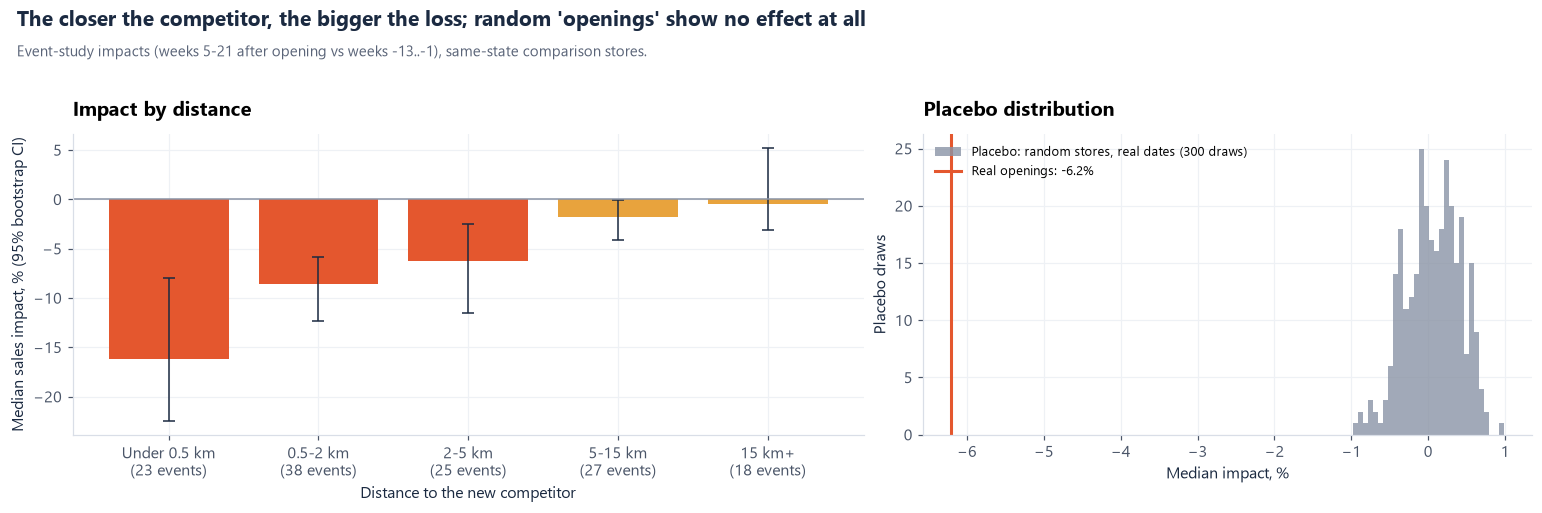

In [16]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
x = np.arange(len(dist_tab))
a1.bar(x, dist_tab["median impact"] * 100, color=[PALETTE["coral"] if v < -0.05 else PALETTE["amber"] if v < 0 else PALETTE["teal"] for v in dist_tab["median impact"]])
a1.errorbar(x, dist_tab["median impact"] * 100, yerr=[(dist_tab["median impact"] - dist_tab["CI low"]) * 100, (dist_tab["CI high"] - dist_tab["median impact"]) * 100],
            fmt="none", ecolor=PALETTE["ink"], capsize=4, lw=1)
a1.axhline(0, color=PALETTE["grey"], lw=1)
a1.set_xticks(x, [f"{b}\n({n} events)" for b, n in zip(dist_tab.index, dist_tab["events"])])
a1.set(ylabel="Median sales impact, % (95% bootstrap CI)", xlabel="Distance to the new competitor", title="Impact by distance")
a2.hist(placebo * 100, bins=30, color=PALETTE["grey"], alpha=0.8, label="Placebo: random stores, real dates (300 draws)")
a2.axvline(eff.median() * 100, color=PALETTE["coral"], lw=2, label=f"Real openings: {eff.median():+.1%}")
a2.set(xlabel="Median impact, %", ylabel="Placebo draws", title="Placebo distribution")
a2.legend(fontsize=8.5, loc="upper left")
fig_title(fig, "The closer the competitor, the bigger the loss; random 'openings' show no effect at all",
          "Event-study impacts (weeks 5-21 after opening vs weeks -13..-1), same-state comparison stores.")
savefig(fig, "03-competitor-distance-placebo", FIG); plt.show()

The loss falls steadily with distance:

| Distance to the new competitor | Median impact |
|---|---|
| Under 500 m | −16% (65% of these stores lose 10%+) |
| 0.5-2 km | −9% |
| 2-5 km | −6% |
| Beyond 5 km | under 2% |

The Spearman correlation between impact and log distance is +0.58. A confounder would have to track distance this
closely to explain the result; a causal effect predicts exactly this pattern.

### B5. Robustness to the comparison group

In [17]:
alt = {}
for lab, ctrl in [("Competitor open before Jul 2012 (main)", controls),
                  ("+ stores with no recorded opening date", stores.loc[(stores["CompOpen"] < "2012-07-01") | stores["CompOpen"].isna(), "Store"]),
                  ("Whole network (as in the ETL)", stores["Store"])]:
    Ea = F.event_profile(F.relative_weekly_sales(fact, state_of, ctrl), treated["Store"], treated["CompOpen"])
    ea = F.event_effects(Ea)
    alt[lab] = {"events": len(Ea), "comparison stores": len(ctrl), "median impact": ea.median(), "mean impact": np.expm1(Ea.loc[:, 5:21].mean(axis=1).mean()),
                "largest |lead|": Ea.loc[:, -13:-1].mean().abs().max()}
alt = pd.DataFrame(alt).T
display(alt.style.format({"events": "{:.0f}", "comparison stores": "{:.0f}", "median impact": "{:+.1%}", "mean impact": "{:+.1%}", "largest |lead|": "{:.3f}"}))

,events,comparison stores,median impact,mean impact,largest |lead|
Competitor open before Jul 2012 (main),131,508,-6.2%,-7.9%,0.008
+ stores with no recorded opening date,131,862,-6.5%,-8.0%,0.006
Whole network (as in the ETL),131,1115,-6.2%,-7.6%,0.007


The answer does not depend on the comparison group. Across three definitions the median is −6.2% to −6.5% and the
mean −7.6% to −8.0%, with flat leads in each.

### B6. Limitations of the competitor estimate

* **Where competitors open is not random.** They choose growing locations. If a treated store's area was growing, the
  estimate is biased towards zero, so the true loss would be larger. Flat pre-trends argue against selection on recent
  trends, but cannot rule out selection on future ones.
* **Timing is known only to the month.** The first four weeks mix days before and after the opening, which is why the
  effect window starts at week 5.
* **Only the nearest competitor is recorded, in a 2015 snapshot.** An opening that did not become a store's nearest
  competitor is invisible, and comparison stores may have had such openings. That also biases towards zero.
* **Spill-overs.** A new competitor may also take sales from nearby comparison stores, which would make the comparison
  group look worse and the effect smaller.
* **Survivorship.** A store that closed after a competitor opened would not be in the data.
* **Exclusions.** 10 of the 141 openings in the window lack enough data (mostly the H2 2014 gap) and are dropped.

## Recommendation

| Question | Finding | Action |
|---|---|---|
| Do promotions work? | Yes: +39% (CI +37% to +41%) on daily sales after controls; half traffic, half basket; no dip the following week | Keep the calendar; plan stock and staff for +39% (+62% on Mondays) |
| Where should promotion tests focus? | The lift is front-loaded (Mon +62%, Fri +25%) and weakest in format B (+18%) | Test shorter (Mon-Wed) promotions and a different mechanic for format B; randomise by store cluster and week, powered on weeks |
| Does the loyalty promotion work? | No measurable effect in its months (−0.3%, CI −0.5% to 0.0%); the −1.9% is seasonality | Run a store-holdout test before renewing, measuring retention as well as sales |
| What does a new competitor cost? | About −8% (CI −10% to −6%) from the second month, no recovery by month six; −16% within 500 m | Feed openings into the forecast (they explain notebook 02's worst stores); re-plan staffing within a month; prioritise retention for stores with a competitor under 2 km |

**How much to trust each estimate.**
* **Promotions** come close to a natural experiment. They alternate week by week across the whole network, so after the
  calendar controls their timing is as good as random.
* **Competitors** rest on a weaker assumption: no selection on *future* trends. But the estimate passes every check
  available (flat pre-trends, placebos, dose-response, alternative comparison groups).

**What is still missing.** Promotion profitability needs margins and promotion costs, which the source does not contain.
With them, the +39% lift and its day-of-week shape feed straight into a break-even calculation per promotion.

In [18]:
elapsed = time.perf_counter() - T_START
report.update_metrics(str(METRICS), "03_causal", {
    "promo_naive": naive.to_dict(), "promo_fe_sales": dec.loc["sales"].to_dict(), "promo_fe_traffic": dec.loc["traffic (customers)"].to_dict(),
    "promo_fe_ticket": dec.loc["ticket (sales per customer)"].to_dict(), "promo_spec_table": spec_tab["lift"].to_dict(),
    "promo_se": se.to_dict(), "promo_post_week": pct(pf.loc["promo_last_week", "coef"]),
    "loyalty_raw": raw_loyal, "loyalty_fe_all": pct(loy["coef"]), "loyalty_fe_ci": [pct(loy["ci_low"]), pct(loy["ci_high"])],
    "etl_events": len(etl_ev), "etl_median_impact": etl_ev["ImpactPct"].median(), "etl_share_losing_10": (etl_ev["ImpactPct"] <= -0.10).mean(),
    "es_events": len(E), "es_median_impact": eff.median(), "es_mean_impact": avg_eff,
    "es_mean_ci": [np.percentile(avg_boot, 2.5), np.percentile(avg_boot, 97.5)], "es_share_losing_10": (eff <= -0.10).mean(),
    "pretrend_max_abs_lead": leads["effect"].abs().max(), "placebo_median": float(np.median(placebo)),
    "placebo_95": [float(np.percentile(placebo, 2.5)), float(np.percentile(placebo, 97.5))], "placebo_p": p_perm,
    "placebo_shift_52w_median": eff_shift.median(), "impact_by_distance": dist_tab["median impact"].to_dict(), "runtime_seconds": elapsed,
})
print(f"metrics saved; runtime {elapsed / 60:.1f} min")

metrics saved; runtime 1.7 min
